# Matplotlib + Seaborn — Detaylandırma, Renklendirme, Pratik Parametreler

**DS Canlı Ders — 4 Haziran 2026**

> Sınıftan (#44): "Grafik detaylandırma, renklendirme, ek parametreler vs."

## Bugünkü hedef

**Aynı veri** üzerinde işe yarayan **somut** detaylandırmaları göreceğiz:

1. **Matplotlib detaylandırma** — ham → şık dönüşüm
2. **Seaborn** — daha az kodla daha güzel + istatistiksel grafikler
3. **Hangi ne zaman?**

Veri: Eurovision (tanıdığımız set)

In [102]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Veriyi CSV'den oku — DB bağlantısı YOK, ekstra kütüphane YOK
df = pd.read_csv("data/contestants.csv")

print("Şekil:", df.shape)
df.head()

Şekil: (1734, 21)


,year,to_country_id,to_country,performer,song,place_contest,sf_num,running_final,running_sf,place_final,...,place_sf,points_sf,points_tele_final,points_jury_final,points_tele_sf,points_jury_sf,composers,lyricists,lyrics,youtube_url
0,1956,ch,Switzerland,Lys Assia,Refrain,2.0,NaN,2.0,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,Georg Benz Stahl,NaN,"(Refrain d'amour...)\n\nRefrain, couleur du ci...",https://youtube.com/watch?v=IyqIPvOkiRk
1,1956,nl,Netherlands,Jetty Paerl,De Vogels Van Holland,2.0,NaN,1.0,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,Cor Lemaire,Annie M. G. Schmidt,De vogels van Holland zijn zo muzikaal\nZe ler...,https://youtube.com/watch?v=u45UQVGRVPA
2,1956,be,Belgium,Fud Leclerc,Messieurs Les Noyés De La Seine,2.0,NaN,3.0,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,Jacques Say;Jean Miret,Robert Montal,Messieurs les noyés de la Seine\nOuvrez-moi le...,https://youtube.com/watch?v=U9O3sqlyra0
3,1956,de,Germany,Walter Andreas Schwarz,Im Wartesaal Zum Großen Glück,2.0,NaN,4.0,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,Walter Andreas Schwarz,NaN,"Es gibt einen Hafen, da fährt kaum ein Schiff\...",https://youtube.com/watch?v=BDNARIDnmTc
4,1956,fr,France,Mathé Altéry,Le Temps Perdu,2.0,NaN,5.0,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,André Lodge,Rachèle Thoreau,"Chante, carillon\nLe chant du temps perdu\nCha...",https://youtube.com/watch?v=dm1L0XyikKI


---
# 🟠 Bölüm 1 — Matplotlib Detaylandırma

## Aynı grafik, 3 aşama

Bir bar chart — "En çok kazanan 10 ülke". Ham → orta → şık.

In [103]:
# Veriyi hazırla
top10 = (df[df["place_final"] == 1]["to_country"]
         .value_counts()
         .head(10))
print(top10)

to_country
Ireland           7
Sweden            7
Netherlands       5
France            5
Luxembourg        5
United Kingdom    5
Israel            4
Denmark           3
Italy             3
Norway            3
Name: count, dtype: int64


### 🔴 Aşama 1 — Ham (kötü)

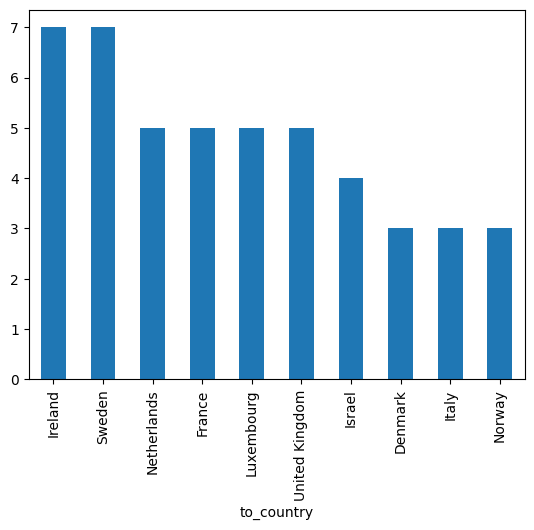

In [108]:
top10.plot.bar()
plt.show()

**Problemleri:**
- Başlık yok, ekseni etiketsiz
- Mavi default — sıkıcı
- X-etiketleri dönük değil — okunmuyor
- Boyut küçük

### 🟡 Aşama 2 — Orta (anlaşılır)

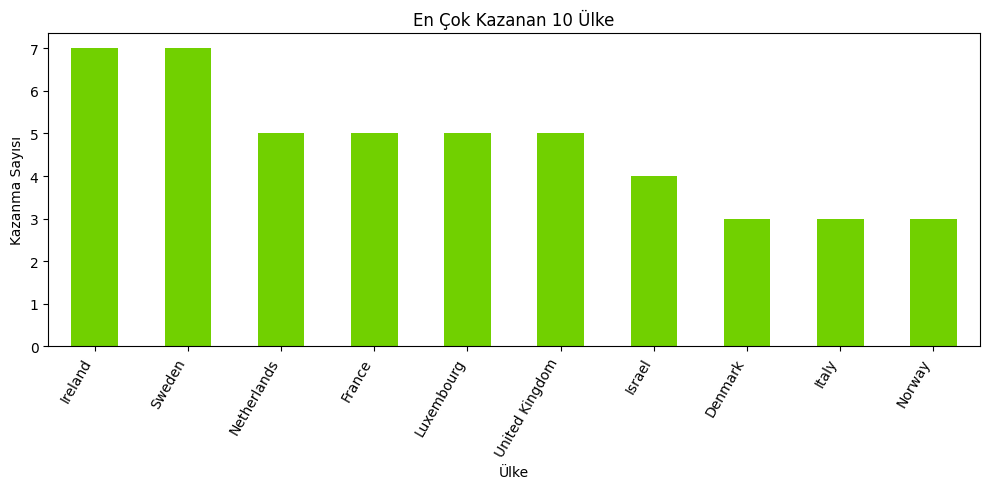

In [112]:
plt.figure(figsize=(10, 5))                  # genişlik=10, yükseklik=5 (inç)
top10.plot.bar(color="#71D000")              # bar rengi (hex kodu)
plt.title("En Çok Kazanan 10 Ülke")           # grafik başlığı
plt.xlabel("Ülke")                            # X ekseni etiketi
plt.ylabel("Kazanma Sayısı")                  # Y ekseni etiketi
plt.xticks(rotation=60, ha="right")           # X etiketlerini 45° eğ, sağa hizala
plt.tight_layout()                            # kenar boşluklarını otomatik ayarla
plt.show()

Üçer satır ekleyince **okunaklı** bir grafik oldu. Ama hâlâ "sunum kalitesi" değil.

### 🟢 Aşama 3 — Şık (sunum kalitesi)

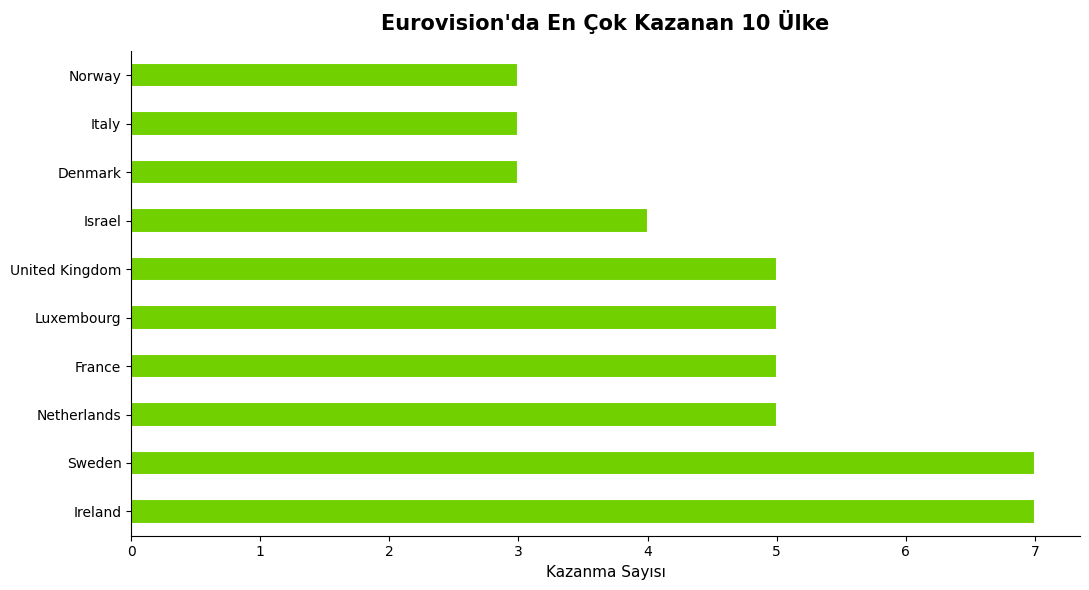

In [121]:
# fig = tüm grafik kutusu, ax = içindeki çizim alanı
fig, ax = plt.subplots(figsize=(11, 6))     # genişlik=11, yükseklik=6

# Yatay bar — uzun ülke isimleri için ideal
top10.plot.barh(
    ax=ax,                          # hangi axes'e çizilecek
    color="#71D000",                # bar rengi
    edgecolor="white",              # bar kenarı (aralar nefes alır)
    linewidth=1.5,                  # kenar çizgisi kalınlığı
)

# Başlık özelleştirme
ax.set_title(
    "Eurovision'da En Çok Kazanan 10 Ülke",
    fontsize=15,                    # yazı boyutu
    fontweight="bold",              # kalın
    pad=15,                         # başlık ile grafik arası boşluk
)
ax.set_xlabel("Kazanma Sayısı", fontsize=11)
ax.set_ylabel("")                   # ülke isimleri zaten net → etiket gereksiz

# # Kenar çizgilerini sil (üst + sağ) — modern minimal görünüm
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ax.grid(axis="x", alpha=0.3)        # sadece x-grid (saydam)
plt.tight_layout()
plt.show()

**Eklediklerimiz:**
- `figsize=(11, 6)` — büyük boyut
- Yatay bar (`barh`) — uzun isimler okunaklı
- `[::-1]` ile en çok yukarıda
- `edgecolor="white"` — barlar arasında nefes
- `pad=15` — başlık biraz nefes alsın
- `spines` — üst/sağ çizgileri kaldır (modern görünüm)
- Bar uçlarına sayıları manuel yazma
- Sadece x-grid (yatay bar olduğu için)

---
## Renk Yöntemleri (4 yol)

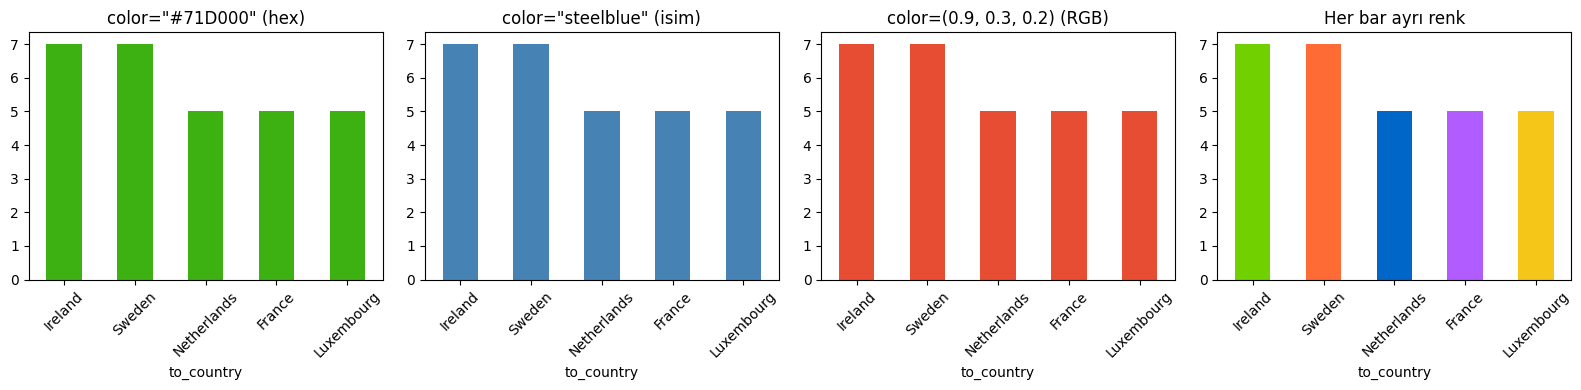

In [124]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# 1. Hex — code2work renk
top10.head(5).plot.bar(ax=axes[0], color="#3DB112")
axes[0].set_title('color="#71D000" (hex)')
axes[0].tick_params(axis="x", rotation=45)     # X tick etiketlerini 45° eğ

# 2. İsim — matplotlib bilinen renkler
top10.head(5).plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title('color="steelblue" (isim)')
axes[1].tick_params(axis="x", rotation=45)     # X tick etiketlerini 45° eğ

# 3. RGB tuple — 0-1 arası 3 sayı (R, G, B)
top10.head(5).plot.bar(ax=axes[2], color=(0.9, 0.3, 0.2))
axes[2].set_title('color=(0.9, 0.3, 0.2) (RGB)')
axes[2].tick_params(axis="x", rotation=45)     # X tick etiketlerini 45° eğ

# 4. Her bar'a ayrı renk — liste ver
renkler = ["#71D000", "#FF6B35", "#0066C8", "#B15CFF", "#F5C518"]
top10.head(5).plot.bar(ax=axes[3], color=renkler)
axes[3].set_title('Her bar ayrı renk')
axes[3].tick_params(axis="x", rotation=45)     # X tick etiketlerini 45° eğ

plt.tight_layout()
plt.show()

> **İpucu:** matplotlib'in tanıdığı 1000+ named color var — `"crimson"`, `"navy"`, `"olive"`, `"coral"`... [Tam liste](https://matplotlib.org/stable/gallery/color/named_colors.html)

---
## Annotation — Belirli noktayı işaretle

"İşte Türkiye birinci olduğu yıl" diyebilmek için.

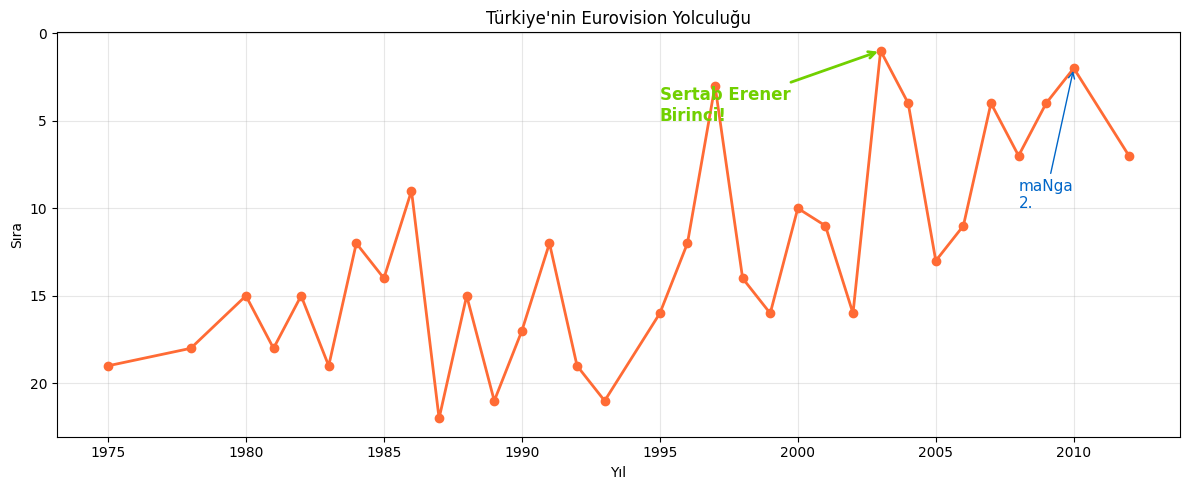

In [137]:
# Türkiye'nin yıllara göre sırası
tr = df[(df["to_country"] == "Turkey") & df["place_final"].notna()].sort_values("year")
# print(tr)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    tr["year"], tr["place_final"],
    marker="o",              # nokta işareti — alternatifler: "s" kare, "^" üçgen, "D" elmas,
                              #                                "*" yıldız, "x" çarpı, "+" artı, "." nokta
    color="#FF6B35",         # çizgi rengi (turuncu)
    linewidth=2,             # çizgi kalınlığı (1 ince, 3+ kalın)
)
ax.invert_yaxis()            # Y'yi ters çevir → 1 üstte, 26 altta
ax.set_title("Türkiye'nin Eurovision Yolculuğu")
ax.set_xlabel("Yıl")
ax.set_ylabel("Sıra")
ax.grid(alpha=0.3)           # saydam grid (0=görünmez, 1=tam opak)

# # Annotation #1 — Sertab kazandı (ok ile vurgu)
ax.annotate(
    "Sertab Erener\nBirinci!",        # yazılacak metin (\n = satır atla)
    xy=(2003, 1),                      # OK'un UCU — vurgulanan nokta
    xytext=(1995, 5),                   # YAZININ konumu (ok'tan uzak)
    fontsize=12,
    fontweight="bold",
    color="#71D000",                    # yazı + ok rengi
    arrowprops=dict(
        arrowstyle="->",                # ok şekli — alternatifler: "<-", "<->", "-|>", "fancy", "simple"
        color="#71D000",
        lw=2,                           # line width (kalınlık)
    ),
)

# # Annotation #2 — maNga 2. olma
ax.annotate(
    "maNga\n2.",
    xy=(2010, 2), 
    xytext=(2008, 10),
    fontsize=11, color="#0066C8",
    arrowprops=dict(arrowstyle="->", color="#0066C8"),
)

plt.tight_layout()
plt.show()

> **`annotate()`** = grafiğin üstüne yazı + ok ekle. Önemli noktaları **vurgulamak** için müthiş.

---
## Subplot — Birden Fazla Grafik Yan Yana

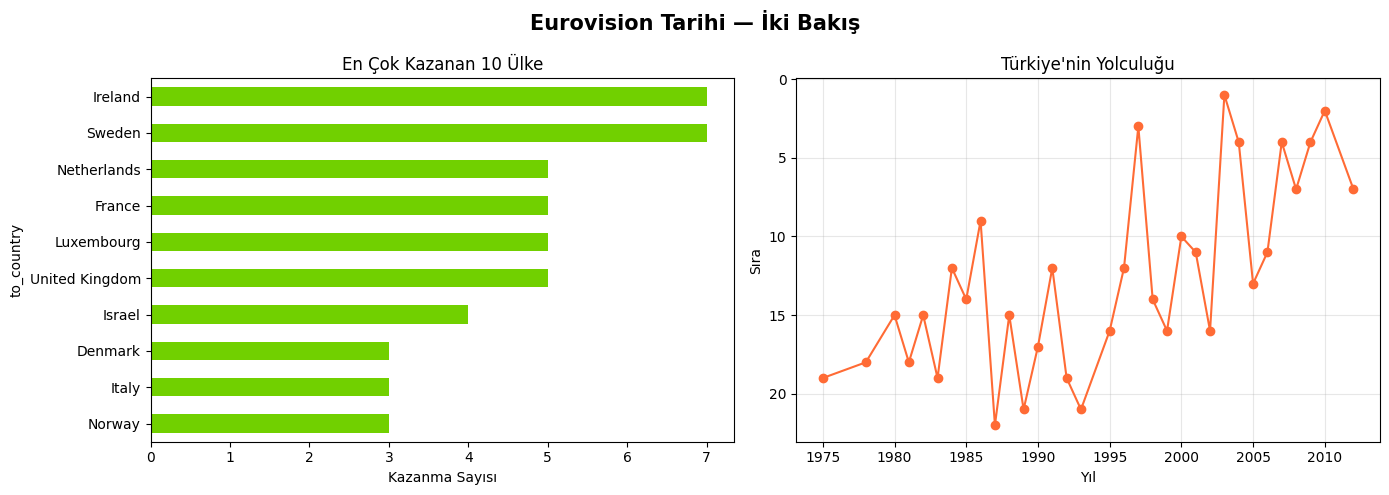

In [139]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sol: en çok kazanan
top10[::-1].plot.barh(ax=axes[0], color="#71D000")
axes[0].set_title("En Çok Kazanan 10 Ülke")
axes[0].set_xlabel("Kazanma Sayısı")

# Sağ: Türkiye yıl yıl
axes[1].plot(tr["year"], tr["place_final"], marker="o", color="#FF6B35")
axes[1].invert_yaxis()
axes[1].set_title("Türkiye'nin Yolculuğu")
axes[1].set_xlabel("Yıl")
axes[1].set_ylabel("Sıra")
axes[1].grid(alpha=0.3)

fig.suptitle("Eurovision Tarihi — İki Bakış", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

> `plt.subplots(satır, sütun)` → grid halinde grafik.
> Daha karmaşık layout için: `plt.subplots(2, 3)` = 6 grafik.

---
## Twin Axes — Aynı Grafikte İki Y Ekseni

Farklı ölçekli iki şeyi yan yana göstermek için **süper kullanışlı**.

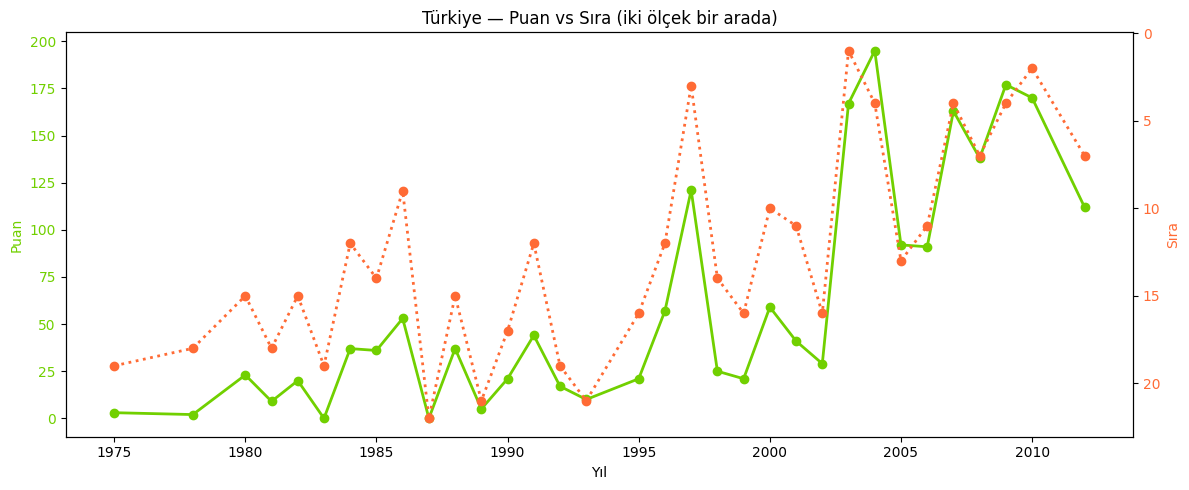

In [144]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# === SOL Y EKSENİ: PUAN (büyük sayı, 0-200) ===
ax1.plot(
    tr["year"], 
    tr["points_final"],
    color="#71D000",         # yeşil → puan
    marker="o",              # yuvarlak işaret
    linewidth=2,
    label="Puan",            # legend için
)
ax1.set_xlabel("Yıl")
ax1.set_ylabel("Puan", color="#71D000")             # etiket de yeşil
ax1.tick_params(axis="y", labelcolor="#71D000")     # Y tick'leri de yeşil

# === SAĞ Y EKSENİ: SIRA (küçük sayı, 1-26) ===
ax2 = ax1.twinx()            # ← SİHİR: aynı X, yeni Y ekseni oluştur
ax2.plot(
    tr["year"], 
    tr["place_final"],
    color="#FF6B35",         # turuncu → sıra
    marker="o",              # KARE işareti (square) — farklı sembol = farklı seri
    linewidth=2,
    label="Sıra",
    linestyle=":",          # KESIK çizgi — alternatifler: "-" sürekli, "-." kesik-nokta, ":" noktalı
)
ax2.invert_yaxis()           # sıra ters → 1 üstte
ax2.set_ylabel("Sıra", color="#FF6B35")
ax2.tick_params(axis="y", labelcolor="#FF6B35")

plt.title("Türkiye — Puan vs Sıra (iki ölçek bir arada)")
plt.tight_layout()
plt.show()

> **`ax.twinx()`** = aynı x ekseni, ikinci y ekseni.
> Para birimi vs. miktar, sıcaklık vs. yağış, satış vs. tıklama gibi senaryolarda hayat kurtarır.

---
# 🟣 Bölüm 2 — Seaborn

## Neden Seaborn?

Seaborn **matplotlib'in üstüne kurulu** — `import seaborn as sns` deyince yine matplotlib kullanıyorsun. Ama:

1. 🎨 **Hazır şık default'lar** — uğraşmadan güzel görünür
2. 🎯 **`hue` parametresi** — tek satırla gruplama
3. 📊 **İstatistiksel grafikler** — violinplot, heatmap... hazır

## Aynı bar chart — sns vs plt

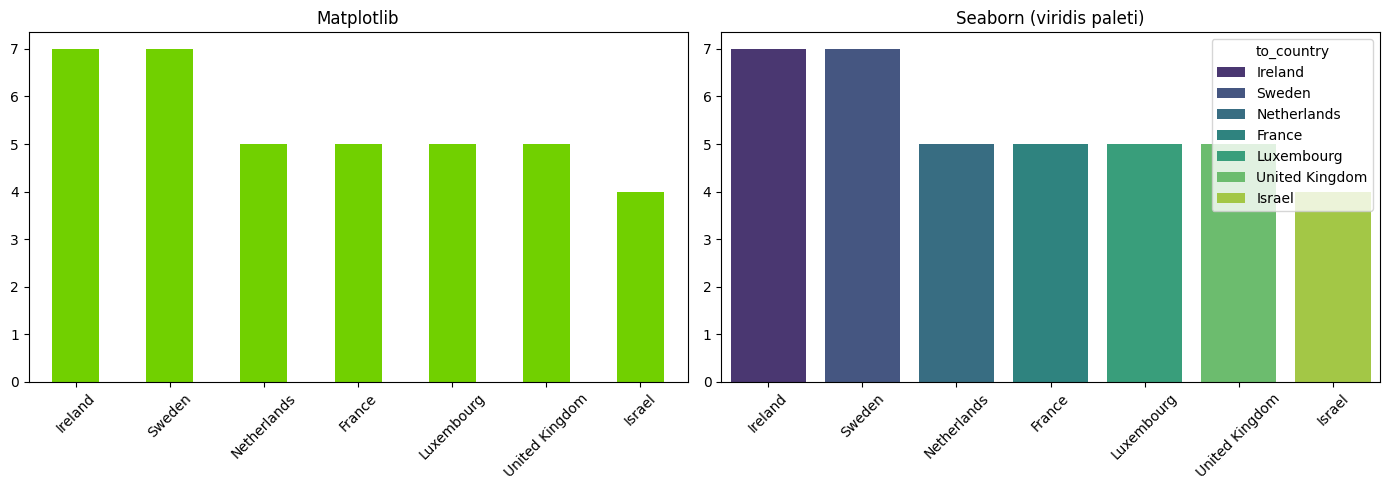

In [149]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matplotlib
top10.head(7).plot.bar(ax=axes[0], color="#71D000")
axes[0].set_title("Matplotlib")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)     # X tick etiketlerini 45° eğ

# Seaborn — daha az kod, hazır palette
# Not: yeni seaborn'da palette için hue=x + legend=False vermek gerekiyor
sns.barplot(
    x=top10.head(7).index,
    y=top10.head(7).values,
    hue=top10.head(7).index,    # hue = "renge göre grupla" — asıl gücünü sonraki örnekte göreceğiz.
                                 # Burada palette kullanabilmek için x ile aynı veriyi veriyoruz (yeni seaborn şartı)
    palette="viridis",          # renk paleti — hazır gelen renk seti
                                 # Sürekli (sıralı):   "viridis", "plasma", "rocket", "YlGnBu"
                                 # Kategorik (ayrık):  "Set2", "deep", "pastel", "muted"
                                 # Diverging (zıt):    "coolwarm", "RdBu", "Spectral"
    legend=True,                # gereksiz legend gizle
    ax=axes[1],
)
axes[1].set_title("Seaborn (viridis paleti)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)     # X tick etiketlerini 45° eğ

plt.tight_layout()
plt.show()

## `hue` — Tek Satırla Gruplama 🎯

Seaborn'un en güçlü tarafı bu.

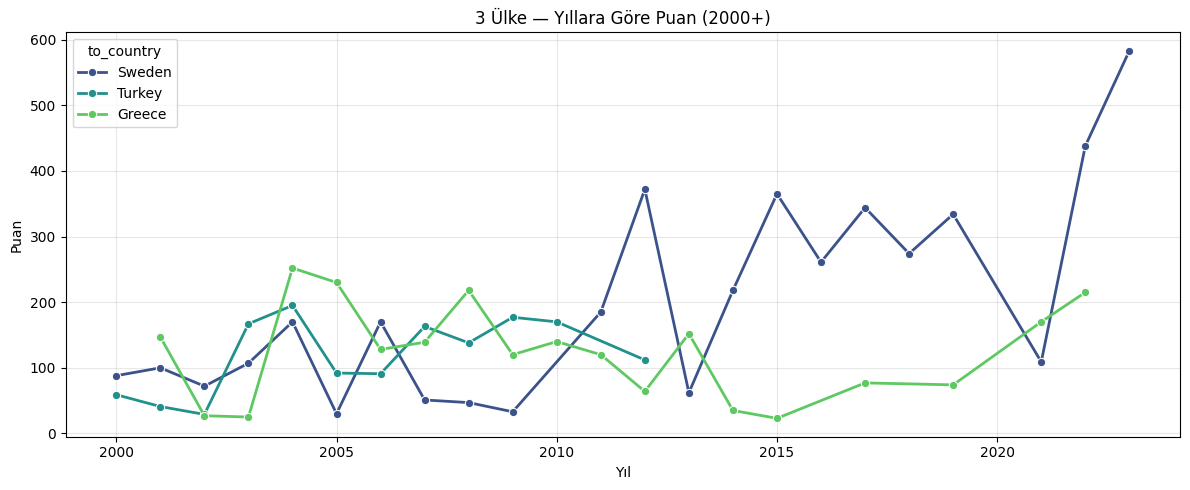

In [153]:
# 3 ülke, yıllara göre puanları — hepsi tek grafikte
df_son = df[(df["to_country"].isin(["Turkey", "Sweden", "Greece"])) &     # 3 ülke filtrele
            (df["year"] >= 2000) &                                          # 2000 sonrası
            (df["points_final"].notna())]                                   # null olmayan puanlar

# hue ne yapar?
#   "Veriyi şu kolona göre RENGE AYIR"
#   to_country = 3 farklı ülke → otomatik 3 ayrı çizgi, 3 ayrı renk, legend hazır
#   hue OLMASA → tüm satırlar tek çizgi olurdu, kim kim belli olmazdı
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=df_son,                # veri kaynağı (DataFrame)
    x="year",                   # X ekseninde hangi kolon
    y="points_final",           # Y ekseninde hangi kolon
    hue="to_country",           # ← SİHİR: bu kolona göre renge ayır + legend ekle
                                 # alternatifler: herhangi bir KATEGORİK kolon
                                 #   "song"  → her şarkı ayrı renk (çok olur, karmaşa)
                                 #   "year"  → her yıl ayrı renk
                                 # ipucu: 2-8 kategori en okunaklı sonucu verir
    palette="viridis",          # renk paleti — hazır gelen renk seti
    marker="o",                 # her noktada işaret
    linewidth=2,
)
plt.title("3 Ülke — Yıllara Göre Puan (2000+)")
plt.xlabel("Yıl")
plt.ylabel("Puan")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

> **`hue="kolon"`** = o kolona göre renkle ayır. 3 ayrı plt.plot() çağrısı yerine **tek satır**.
> Legend otomatik geliyor. Renkler otomatik.

---
## Heatmap — Önce Basit Bir Örnek

Heatmap = **matris (tablo)** şeklindeki veriyi **renklerle** göster. Yüksek değer → koyu, düşük → açık.

Önce çok basit bir örnekle mantığı görelim.

        Matematik  Fizik  Kimya  Biyoloji
Ali            85     70     55        92
Ayşe           60     90     75        65
Mehmet         95     80     88        70


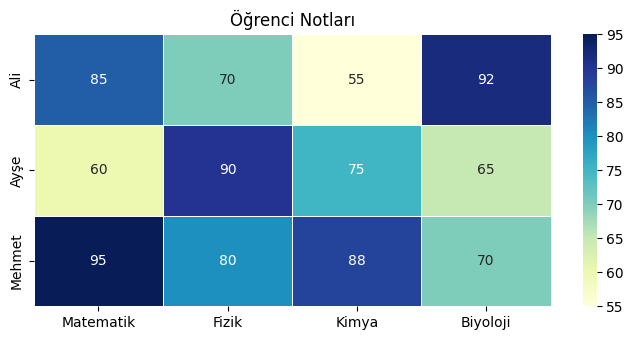

In [165]:
# 3 öğrenci, 4 dersin notları — küçük bir matris
notlar = pd.DataFrame(
    {
        "Matematik": [85, 60, 95],
        "Fizik":     [70, 90, 80],
        "Kimya":     [55, 75, 88],
        "Biyoloji":  [92, 65, 70],
    },
    index=["Ali", "Ayşe", "Mehmet"],
)
print(notlar)

plt.figure(figsize=(7, 3.5))
sns.heatmap(
    notlar,
    cmap="YlGnBu",          # renk paleti (sarı→yeşil→mavi)
    annot=True,             # her hücreye değeri yaz
    fmt="d",                # format: tam sayı (integer)
    linewidths=0.5,         # hücreler arası ince çizgi
    linecolor="white",
)
plt.title("Öğrenci Notları")
plt.tight_layout()
plt.show()

> Tablo aynı tablo ama gözle bakınca **kim hangi derste iyi/kötü** anında çıkıyor.
> Sayılarla aynı bilgi var → ama beyin renkleri çok daha hızlı tarıyor.
>
> Şimdi aynı mantığı **gerçek bir veriyle** (Eurovision oyları) deneyelim.

---
## Heatmap — Gerçek Veri (Eurovision oyları)

Aynı mantık, daha büyük veri. Eurovision'un ünlü "komşuluk efsanesi"ne bakalım.

(10, 10)


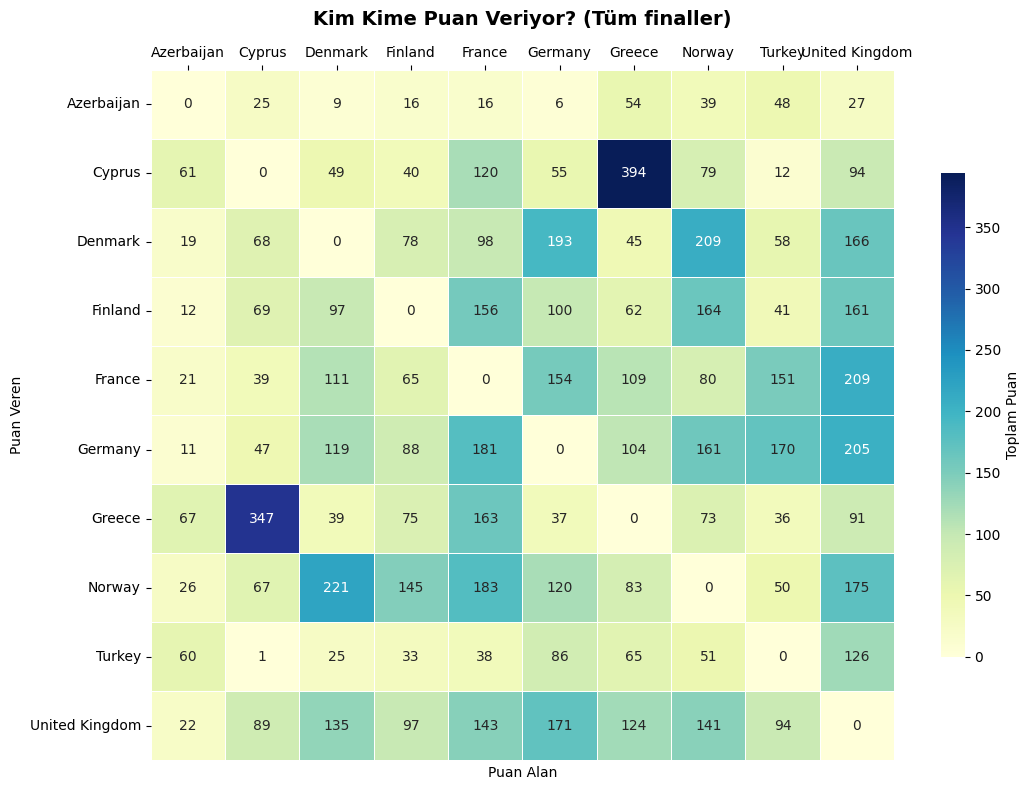

In [173]:
# Komşuluk heatmap'i için votes verisi
df_votes = pd.read_csv("data/votes.csv")

# Sadece final + ülke kendisine puan vermesin
df_votes = df_votes[
    (df_votes["round"] == "final") &
    (df_votes["from_country"] != df_votes["to_country"])
]

# Ülke isimlerini bul (votes'ta kod var, contestants'tan tam ismi al)
country_map = df[["to_country_id", "to_country"]].drop_duplicates().set_index("to_country_id")["to_country"].to_dict()
df_votes["from_country_name"] = df_votes["from_country"].map(country_map)
df_votes["to_country_name"]   = df_votes["to_country"].map(country_map)

# Toplam puanlar
df_pivot_src = df_votes.groupby(["from_country_name", "to_country_name"])["total_points"].sum().reset_index()

aktif = ["Azerbaijan", "Norway", "Denmark", "Finland",
         "Greece", "Cyprus", "Turkey",
         "Germany", "France", "United Kingdom"]
df_filt = df_pivot_src[df_pivot_src["from_country_name"].isin(aktif) & df_pivot_src["to_country_name"].isin(aktif)]
# print(df_filt)
# Pivot tablo: satır=veren, sütun=alan, hücre=puan
pivot = df_filt.pivot_table(
    index="from_country_name",  # satırlar
    columns="to_country_name",  # sütunlar
    values="total_points",      # hücre değeri
    fill_value=0,               # boş hücreleri 0 yap
)
# print(pivot)

print(pivot.shape)

plt.figure(figsize=(11, 8))
sns.heatmap(
    pivot,
    cmap="YlGnBu",              # renk paleti (sarı→yeşil→mavi)
    annot=True,                 # her hücrenin değerini yaz
    fmt=".0f",                  # format: ondalıksız (.2f olsa 2 ondalık)
    linewidths=0.5,             # hücreler arası ince çizgi
    linecolor="white",          # çizgi rengi
    cbar_kws={                  # color bar (yan çubuk) ayarları
        "label": "Toplam Puan",
        "shrink": 0.7,          # çubuğu küçült (0-1 arası)
    },
)
ax = plt.gca()          # mevcut axes'i al
ax.xaxis.tick_top()
plt.title("Kim Kime Puan Veriyor? (Tüm finaller)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Puan Alan")
plt.ylabel("Puan Veren")
plt.tight_layout()
plt.show()

**Heatmap'in pratik parametreleri:**
- `cmap="YlGnBu"` — renk paleti
- `annot=True` — sayıları göster
- `fmt=".0f"` — tam sayı (.2f olsa 2 ondalık)
- `linewidths` + `linecolor` — hücreleri ayır
- `cbar_kws` — yan çubuğu özelleştir

---
# 🎯 Bölüm 3 — Hangi Ne Zaman?

| Senaryo | Tercih |
|---------|--------|
| Tam kontrol istiyorum | matplotlib |
| Hızlıca şık çıktı | seaborn |
| Gruplama (`hue`) | seaborn |
| Heatmap | seaborn |
| Tek özel annotation | matplotlib |
| Twin axes (iki y) | matplotlib |

> **Pratik tavsiye:** Seaborn ile çiz, matplotlib ile son rötuşları yap.
> `sns.barplot(...)` → sonra `plt.title(...)`, `plt.xticks(rotation=45)` ekleyebilirsin.

---
## 📝 Kapanış

### Bugün öğrendiklerimiz

**Matplotlib:**
- `figsize`, `title`, `xlabel`, `ylabel`, `xticks(rotation=...)`
- `color` (hex, isim, RGB, liste), `edgecolor`, `alpha`, `linewidth`
- `marker`, `linestyle`, `markersize`
- `spines` ile kenar çizgisi kontrol
- `annotate()` ile ok + yazı
- `subplots(satır, sütun)` ile çoklu grafik
- `twinx()` ile iki y ekseni

**Seaborn:**
- `sns.barplot/lineplot/heatmap`
- `hue="kolon"` ile gruplama
- `palette="viridis"` ile renk paleti

### Ev ödevi

- 🟢 **Yeni başlayan**: Bir grafiği ham → orta → şık 3 versiyonunu yap. Eurovision verisini kullan.
- 🟠 **Orta**: 2 ülkeyi seç, yıllara göre puan değişimini `hue` ile tek grafikte göster.
- 🟣 **İleri**: Heatmap'i 15 ülkeye çıkar + her ülke için ortalama puan **annotation** ile ekle.

In [ ]:
# Bitti — DB bağlantısı olmadığı için kapatacak bir şey yok